In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_recall_curve, average_precision_score,
                             PrecisionRecallDisplay)
from sklearn.pipeline import make_pipeline

url_red = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
url_white = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

red = pd.read_csv(url_red, sep=';')
white = pd.read_csv(url_white, sep=';')

red['type'] = 'red'
white['type'] = 'white'

df = pd.concat([red, white], ignore_index=True)

df['is_good'] = (df['quality'] >= 7).astype(int)

print("Распределение классов:")
print(df['is_good'].value_counts(normalize=True))

Распределение классов:
is_good
0    0.803448
1    0.196552
Name: proportion, dtype: float64


In [8]:
feature_cols = [c for c in df.columns if c not in ['quality', 'is_good', 'type']]
X = df[feature_cols]
y = df['is_good']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [9]:
knn = KNeighborsClassifier(n_neighbors=5, weights='distance')
knn.fit(X_train_scaled, y_train)

svm = SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42)
svm.fit(X_train_scaled, y_train)

tree = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)
tree.fit(X_train, y_train)

def evaluate_model(name, model, X_test_data, y_test_data):
    y_pred = model.predict(X_test_data)
    print(f"\n=== {name} ===")
    print(classification_report(y_test_data, y_pred, target_names=['Bad', 'Good']))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test_data, y_pred))

evaluate_model("KNN", knn, X_test_scaled, y_test)
evaluate_model("SVM (Balanced)", svm, X_test_scaled, y_test)
evaluate_model("Decision Tree (Balanced)", tree, X_test, y_test)

C:\Users\carantoin\PycharmProjects\JupyterProject10\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



=== KNN ===
              precision    recall  f1-score   support

         Bad       0.90      0.93      0.92      1567
        Good       0.67      0.59      0.63       383

    accuracy                           0.86      1950
   macro avg       0.79      0.76      0.77      1950
weighted avg       0.86      0.86      0.86      1950

Confusion Matrix:
[[1456  111]
 [ 158  225]]

=== SVM (Balanced) ===
              precision    recall  f1-score   support

         Bad       0.94      0.73      0.82      1567
        Good       0.43      0.83      0.56       383

    accuracy                           0.75      1950
   macro avg       0.69      0.78      0.69      1950
weighted avg       0.84      0.75      0.77      1950

Confusion Matrix:
[[1146  421]
 [  67  316]]

=== Decision Tree (Balanced) ===
              precision    recall  f1-score   support

         Bad       0.94      0.68      0.79      1567
        Good       0.39      0.81      0.52       383

    accuracy         

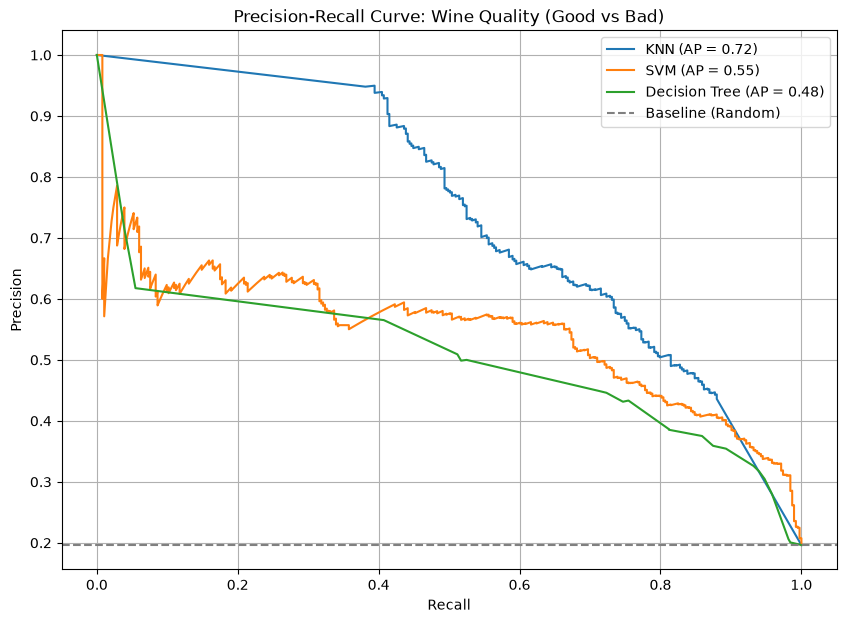

In [10]:
fig, ax = plt.subplots(figsize=(10, 7))

y_scores_knn = knn.predict_proba(X_test_scaled)[:, 1]
precision_knn, recall_knn, _ = precision_recall_curve(y_test, y_scores_knn)
ap_knn = average_precision_score(y_test, y_scores_knn)
ax.plot(recall_knn, precision_knn, label=f'KNN (AP = {ap_knn:.2f})')

y_scores_svm = svm.predict_proba(X_test_scaled)[:, 1]
precision_svm, recall_svm, _ = precision_recall_curve(y_test, y_scores_svm)
ap_svm = average_precision_score(y_test, y_scores_svm)
ax.plot(recall_svm, precision_svm, label=f'SVM (AP = {ap_svm:.2f})')

y_scores_tree = tree.predict_proba(X_test)[:, 1]
precision_tree, recall_tree, _ = precision_recall_curve(y_test, y_scores_tree)
ap_tree = average_precision_score(y_test, y_scores_tree)
ax.plot(recall_tree, precision_tree, label=f'Decision Tree (AP = {ap_tree:.2f})')

ax.axhline(y=y_test.mean(), color='grey', linestyle='--', label='Baseline (Random)')

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve: Wine Quality (Good vs Bad)')
ax.legend(loc='best')
ax.grid(True)
plt.show()